# 01 — Terrace 28


## Imports and repository paths


In [1]:
from pathlib import Path
import sys

WORKING_DIR = Path.cwd().resolve()
ROOT = next((folder for folder in (WORKING_DIR, *WORKING_DIR.parents)
             if (folder / "utils/site_analysis.py").is_file()
             and (folder / "data/accelerometer").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Run this notebook from the repository or its processing folder.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import display
from utils import hvsr_tools as hv
from utils import plotting as hp
from utils import site_analysis as sa
from utils.analysis_figure import FIGURE_CONTROLS, make_analysis_figure


## Site and processing parameters


In [2]:
SITE = sa.SITE_BY_KEY['01_terrace_28']
PARAMS = sa.BASE_PARAMS
FIGURE_DIR = ROOT / "main/02_hvsr_processing/figures" / SITE.key
DATA_DIR = ROOT / "main/02_hvsr_processing/data" / SITE.key
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR.mkdir(parents=True, exist_ok=True)
display(pd.Series({
    "field_label": SITE.label,
    "session_id": SITE.session_id,
    "processing_parameters": PARAMS.to_dict(),
}, name="Analysis setup"))


field_label                                                     Terraza 28
session_id                          CBUCF_titanSMA_1614_20230519_213500_02
processing_parameters    {'window_length_s': 120.0, 'overlap_pct': 0.0,...
Name: Analysis setup, dtype: object

## Recording and HVSR processing


In [3]:
analysis = sa.analyze_site(ROOT, SITE.key, PARAMS)
summary = sa.site_summary([analysis])
display(summary.round(3))
display(pd.Series(analysis.quality["metrics"], name="SESAME quality metrics"))


,site_key,session_id,field_label,f0_hz,A0,reliability_count,clarity_count,n_windows,thickness_vs_150_m,thickness_vs_250_m,thickness_vs_350_m
0,01_terrace_28,CBUCF_titanSMA_1614_20230519_213500_02,Terraza 28,10.777,1.194,3,2,5,3.48,5.8,8.119


reliability_count                         3
clarity_count                             2
sesame_passed                         False
retained_fraction                  0.416667
frequency_coverage_complete            True
fn_std_hz                          4.798308
sigma_a_at_peak                     1.15488
R1                                     True
R2                                     True
R3                                     True
C1                                     True
C2                                    False
C3                                    False
C4                                    False
C5                                    False
C6                                     True
time_blocks_complete                  False
block_global_max_deviation_pct          inf
block_tracked_max_deviation_pct         inf
Name: SESAME quality metrics, dtype: object

## Site analysis figure


{'pdf': PosixPath('/home/orincon/ciudad-perdida-hvsr/main/02_hvsr_processing/figures/01_terrace_28/01_terrace_28_analysis.pdf'),
 'svg': PosixPath('/home/orincon/ciudad-perdida-hvsr/main/02_hvsr_processing/figures/01_terrace_28/01_terrace_28_analysis.svg'),
 'png': PosixPath('/home/orincon/ciudad-perdida-hvsr/main/02_hvsr_processing/figures/01_terrace_28/01_terrace_28_analysis.png')}

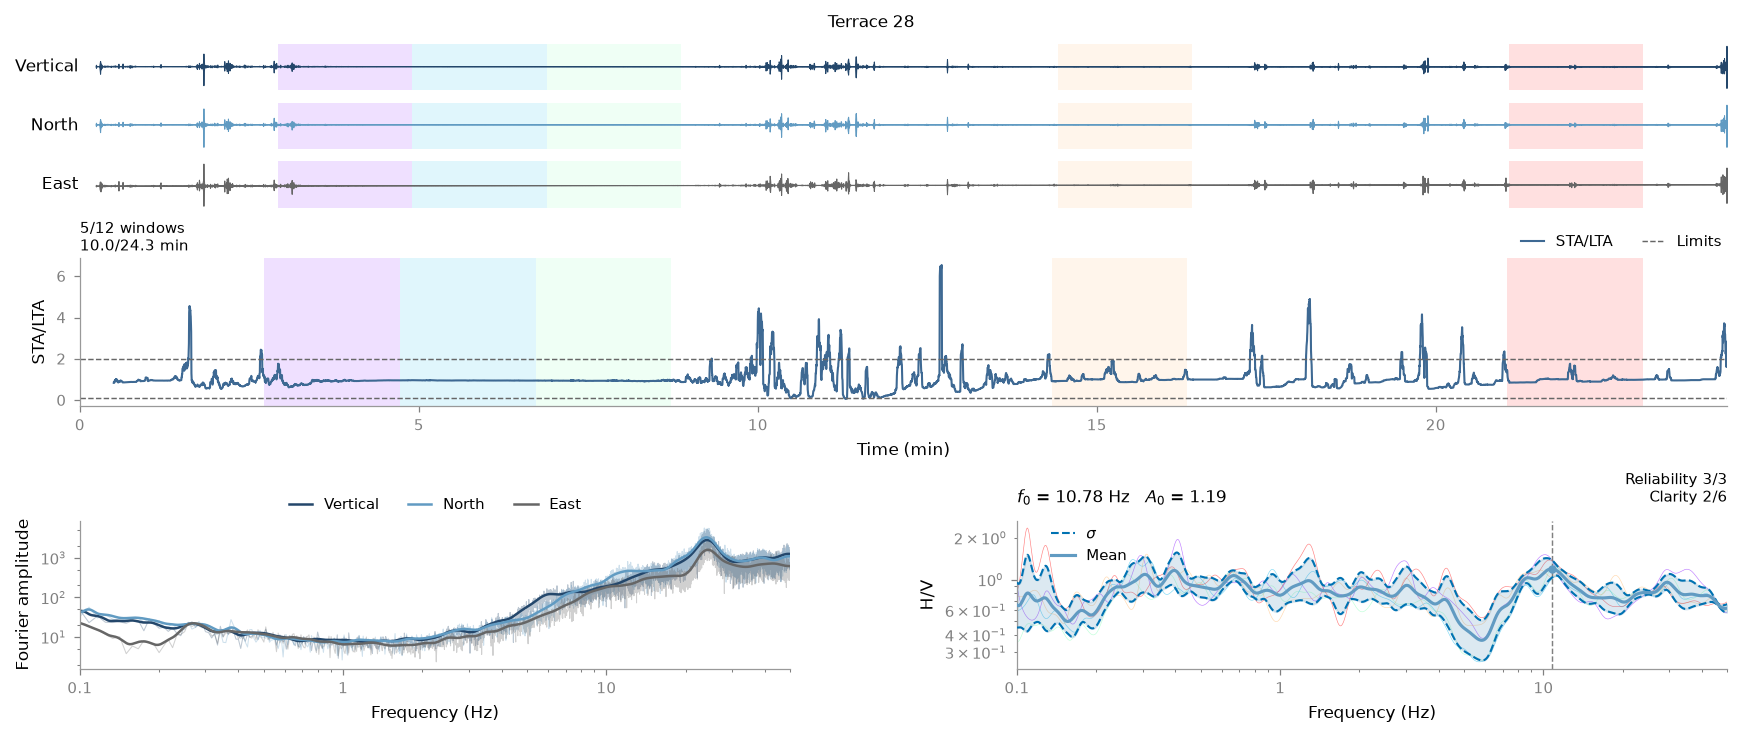

In [4]:
ANALYSIS_STYLE = hp.PaperStyle(width_in=11.5, font_size=8.0, tick_size=7.0,
                                   legend_size=7.0, dpi=300)
FOURIER_DATA = hv.component_fourier_data(analysis.record, analysis.result)
analysis_figure = make_analysis_figure(
    analysis.record,
    analysis.result,
    FOURIER_DATA.smoothed,
    FIGURE_CONTROLS,
    ANALYSIS_STYLE,
    show_windows=True,
    fourier_data=FOURIER_DATA,
)
analysis_figure.suptitle(SITE.figure_label, fontsize=ANALYSIS_STYLE.font_size)
figure_paths = hp.save_figure(
    analysis_figure,
    FIGURE_DIR / f"{SITE.key}_analysis",
    formats=("pdf", "svg", "png"),
    style=ANALYSIS_STYLE,
)
display(figure_paths)


## Data and diagnostics export


In [5]:
summary.to_csv(DATA_DIR / f"{SITE.key}_summary.csv", index=False)
data_paths = hv.save_outputs(
    analysis.result,
    DATA_DIR,
    prefix=SITE.key,
    extra={"field_label": SITE.label, "quality": analysis.quality["metrics"]},
)
display(data_paths)


/home/orincon/ciudad-perdida-hvsr/utils/hvsr_tools.py:697: RuntimeWarning: Undefined diagnostic exported as JSON null; review incomplete quality metrics.
  return {key: serializable(item) for key, item in value.items()}


{'curve': PosixPath('/home/orincon/ciudad-perdida-hvsr/main/02_hvsr_processing/data/01_terrace_28/01_terrace_28_curve.csv'),
 'windows': PosixPath('/home/orincon/ciudad-perdida-hvsr/main/02_hvsr_processing/data/01_terrace_28/01_terrace_28_windows.csv'),
 'summary': PosixPath('/home/orincon/ciudad-perdida-hvsr/main/02_hvsr_processing/data/01_terrace_28/01_terrace_28_summary.json'),
 'selection': PosixPath('/home/orincon/ciudad-perdida-hvsr/main/02_hvsr_processing/data/01_terrace_28/01_terrace_28_selection.csv')}